# Migración de aves rapaces sobre Kèköldi, Talamanca
**Proyecto Aplicado 2 · MA-0321 Cálculo Diferencial e Integral · UCR Sede del Sur**
Allison Georgina Monge Navarro · C-06

**Pregunta de decisión:** ¿qué fechas y qué horario debe tener la campaña de voluntariado para registrar la mayor cantidad de aves migratorias?

Este cuaderno sigue la ruta del curso: *datos observados → tasa → integral → verificación → escenarios → decisión*. Toda la matemática está en la carpeta `src/`; aquí se usa y se explica.

> Los datos son simulados con fines didácticos; no son registros oficiales del programa de conteo.

In [1]:
import pandas as pd

from src import escenarios as es
from src import graficos as gr
from src.datos import cargar_base
from src.limpieza import limpiar_conteos, resumen_limpieza
from src.modelo import (
    CurvaDePaso,
    error_relativo,
    mejor_ventana,
    perfil_horario,
    total_diario,
    total_diario_trapecio,
    totales_diarios,
    verificar_total,
)

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Lectura de la base
El Excel se lee directamente (sin copiar valores a mano) y se revisa que tenga las hojas, columnas y unidades esperadas.

In [2]:
base = cargar_base()
p = base.parametros
conteos = base.conteos
print(p)
conteos.head()

Parametros(hi=6.2, hf=17.1, dias_campana=21, horas_turno=6, inicio_tradicional=11.0)


,fecha,hora_inicio,especie,aves_contadas,condicion,hora,dia
0,2026-09-20,07:00,Gavilán aludo,0.000,Nublado,7.000,0
1,2026-09-20,08:00,Gavilán aludo,2.000,Nublado,8.000,0
2,2026-09-20,09:00,Gavilán aludo,3.000,Nublado,9.000,0
3,2026-09-20,10:00,Gavilán aludo,2.000,Nublado,10.000,0
4,2026-09-20,11:00,Gavilán aludo,1.000,Nublado,11.000,0


## 2. Exploración: periodo, unidades y patrones
- **Periodo:** 50 días, del 20 de septiembre al 8 de noviembre de 2026.
- **Unidades:** cada registro es el número de aves de una especie contadas en un bloque de una hora (aves); dividido entre 1 h es una **tasa** (aves/h).
- **Horario observado:** bloques de 7:00 a 15:00, es decir, de 7:00 a 16:00. El vuelo real va de h_i a h_f (hoja *Parametros*).

In [3]:
print(
    "Fechas:",
    conteos["fecha"].min().date(),
    "a",
    conteos["fecha"].max().date(),
    "|",
    conteos["fecha"].nunique(),
    "días",
)
print("Bloques horarios:", sorted(conteos["hora_inicio"].unique()))
print("Registros por especie:")
print(conteos["especie"].value_counts())
conteos.groupby("especie")["aves_contadas"].describe()

Fechas: 2026-09-20 a 2026-11-08 | 50 días
Bloques horarios: ['07:00', '08:00', '09:00', '10:00', '11:00', '12:00', '13:00', '14:00', '15:00']
Registros por especie:
especie
Gavilán aludo           450
Gavilán de Swainson     450
Zopilote cabecirrojo    450
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
especie,,,,,,,,
Gavilán aludo,435.000,"1,419.791","3,002.949",0.000,2.000,140.000,"1,427.500","32,470.000"
Gavilán de Swainson,423.000,647.121,"1,353.257",0.000,0.000,6.000,595.000,"10,407.000"
Zopilote cabecirrojo,434.000,"3,113.710","6,909.603",0.000,6.000,897.500,"3,956.000","113,450.000"


### Patrón por clima
La lluvia reduce el vuelo y además es cuando más faltan conteos.

In [4]:
clima = conteos.groupby("condicion").agg(
    horas=("aves_contadas", "size"),
    horas_sin_conteo=("aves_contadas", lambda s: s.isna().sum()),
    aves_promedio_por_hora=("aves_contadas", "median"),
)
clima

,horas,horas_sin_conteo,aves_promedio_por_hora
condicion,,,
Despejado,594,3,411.000
Lluvia,297,54,6.000
Nublado,459,1,95.500


## 3. Faltantes y atípicos
**Criterio (documentado en `docs/bitacora_supuestos.md`):**
1. *Cero de más:* un conteo de al menos 20 aves que es más de 5 veces el promedio de sus horas vecinas del mismo día.
2. *Horas sin conteo:* valores vacíos (NaN), casi todos en horas con lluvia.

Los dos casos se rellenan **interpolando en línea recta dentro del mismo día**. La columna original `aves_contadas` no se modifica; el valor corregido queda en `aves_limpias`.

In [5]:
limpio = limpiar_conteos(conteos)
display(resumen_limpieza(limpio))
limpio[limpio["correccion"] == "atípico"][
    ["fecha", "hora_inicio", "especie", "condicion", "aves_contadas", "aves_limpias"]
]

correccion,especie,atípico,faltante
0,Gavilán aludo,1,15
1,Gavilán de Swainson,0,27
2,Zopilote cabecirrojo,3,16


,fecha,hora_inicio,especie,condicion,aves_contadas,aves_limpias
113,2026-10-02,12:00,Gavilán aludo,Nublado,"32,470.000","2,304.000"
1063,2026-10-08,08:00,Zopilote cabecirrojo,Lluvia,430.000,71.500
1156,2026-10-18,11:00,Zopilote cabecirrojo,Despejado,"113,450.000","6,248.000"
1336,2026-11-07,11:00,Zopilote cabecirrojo,Despejado,"17,440.000","1,296.000"


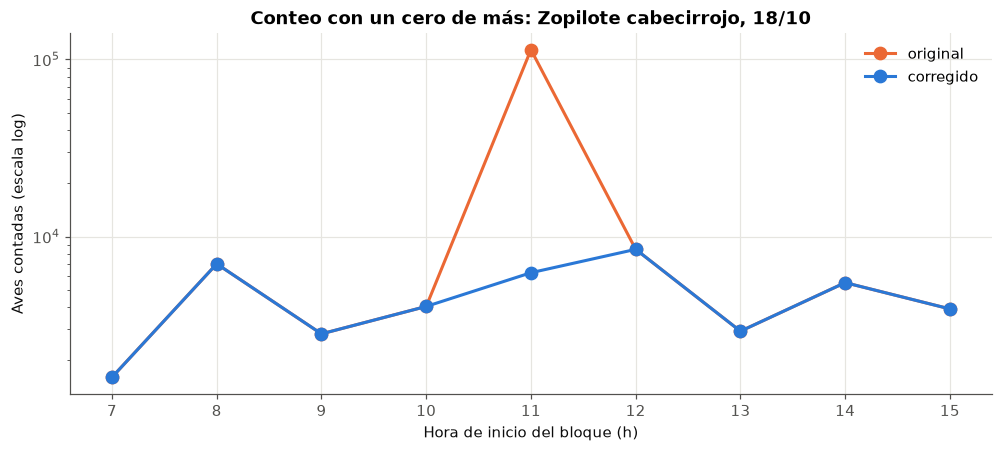

In [6]:
ej = limpio[limpio["correccion"] == "atípico"].sort_values("aves_contadas").iloc[-1]
dia = limpio[(limpio["dia"] == ej["dia"]) & (limpio["especie"] == ej["especie"])]
gr.antes_y_despues(
    dia["aves_contadas"].to_numpy(),
    dia["aves_limpias"].to_numpy(),
    f"Conteo con un cero de más: {ej['especie']}, {ej['fecha']:%d/%m}",
);

## 4. Total diario como integral de la tasa
$$N_d=\int_{h_i}^{h_f} r_d(x)\,dx$$
- Entre 7:00 y 16:00 la tasa se toma constante en cada hora, así que el área de cada bloque es el conteo (aves/h × 1 h = aves).
- Antes de las 7:00 y después de las 16:00 no hay conteo: la tasa se modela como una **recta que llega a cero** en $h_i$ y en $h_f$. Cada cola es un triángulo: $\tfrac12\,(\text{base})(\text{altura})$.

Bloques + triángulos: 45,283 aves
Trapecio (puntos a la mitad de cada hora): 43,906 aves
Error relativo entre los dos métodos: 3.04%


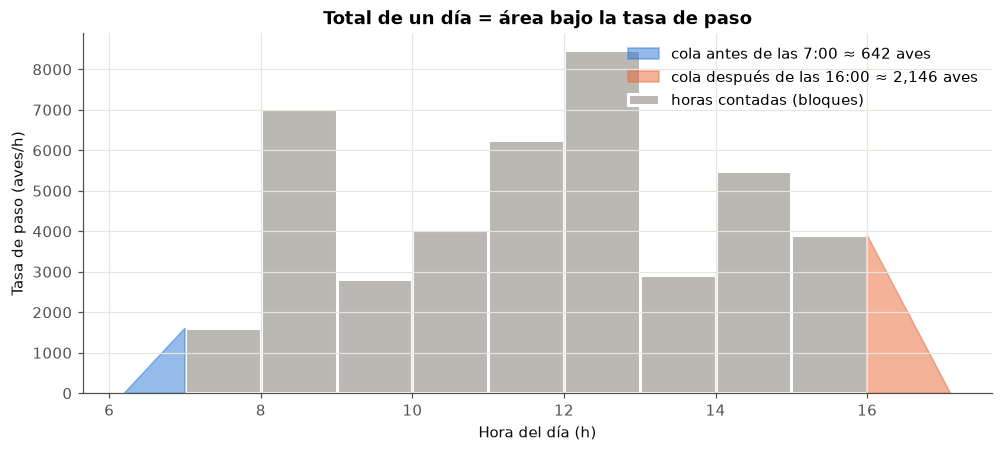

In [7]:
conteo_dia = dia["aves_limpias"].to_numpy()
bloques = total_diario(conteo_dia, p.hi, p.hf)
trap = total_diario_trapecio(conteo_dia, p.hi, p.hf)
print(f"Bloques + triángulos: {bloques:,.0f} aves")
print(f"Trapecio (puntos a la mitad de cada hora): {trap:,.0f} aves")
print(f"Error relativo entre los dos métodos: {error_relativo(trap, bloques):.2%}")
gr.integral_de_un_dia(conteo_dia, p.hi, p.hf, "Total de un día = área bajo la tasa de paso");

In [8]:
totales = totales_diarios(limpio, p.hi, p.hf)
contado = limpio["aves_limpias"].sum()
print(f"Aves contadas (7:00-16:00): {contado:,.0f}")
estimado = totales["Total"].sum()
print(f"Aves estimadas con las colas: {estimado:,.0f}  (+{estimado / contado - 1:.1%})")
totales.head()

Aves contadas (7:00-16:00): 2,126,716
Aves estimadas con las colas: 2,220,998  (+4.4%)


,dia,fecha,Gavilán aludo,Gavilán de Swainson,Zopilote cabecirrojo,Total
0,0,2026-09-20,10.000,0.000,0.000,10.000
1,1,2026-09-21,23.400,0.000,0.000,23.400
2,2,2026-09-22,43.450,0.000,0.000,43.450
3,3,2026-09-23,63.850,0.000,0.000,63.850
4,4,2026-09-24,324.550,0.000,0.000,324.550


## 5. La temporada: total, curva acumulada y fechas clave
$$N=\int_{t_0}^{t_1} n(t)\,dt,\qquad F(t)=\frac1N\int_{t_0}^{t} n(u)\,du,\qquad \bar t=\frac1N\int_{t_0}^{t_1} t\,n(t)\,dt$$
Las fechas del 5, 50 y 95 % salen de resolver $F(t)=p$ por interpolación lineal.

In [9]:
curvas = {e: CurvaDePaso(e, totales["dia"], totales[e]) for e in [*es.ESPECIES, "Total"]}
resumen = pd.DataFrame([c.resumen() for c in curvas.values()]).set_index("especie")
fecha0 = totales["fecha"].min()
for col in ["fecha_5", "fecha_50", "fecha_95", "fecha_media"]:
    resumen[col + "_cal"] = [es.dia_a_fecha(v, fecha0) for v in resumen[col]]
resumen

,total_aves,total_aves_simpson,error_relativo,fecha_5,fecha_50,fecha_95,fecha_media,dispersion_dias,fecha_5_cal,fecha_50_cal,fecha_95_cal,fecha_media_cal
especie,,,,,,,,,,,,
Gavilán aludo,"619,067.450","630,874.633",0.019,12.172,19.628,27.438,19.733,4.559,02/10/2026,10/10/2026,17/10/2026,10/10/2026
Gavilán de Swainson,"297,213.200","306,049.300",0.030,24.178,30.117,36.633,30.249,3.776,14/10/2026,20/10/2026,27/10/2026,20/10/2026
Zopilote cabecirrojo,"1,303,737.500","1,292,020.692",0.009,24.447,34.806,43.706,34.376,5.694,14/10/2026,25/10/2026,03/11/2026,24/10/2026
Total,"2,220,018.150","2,228,944.625",0.004,15.684,30.612,42.254,29.740,8.205,06/10/2026,21/10/2026,01/11/2026,20/10/2026


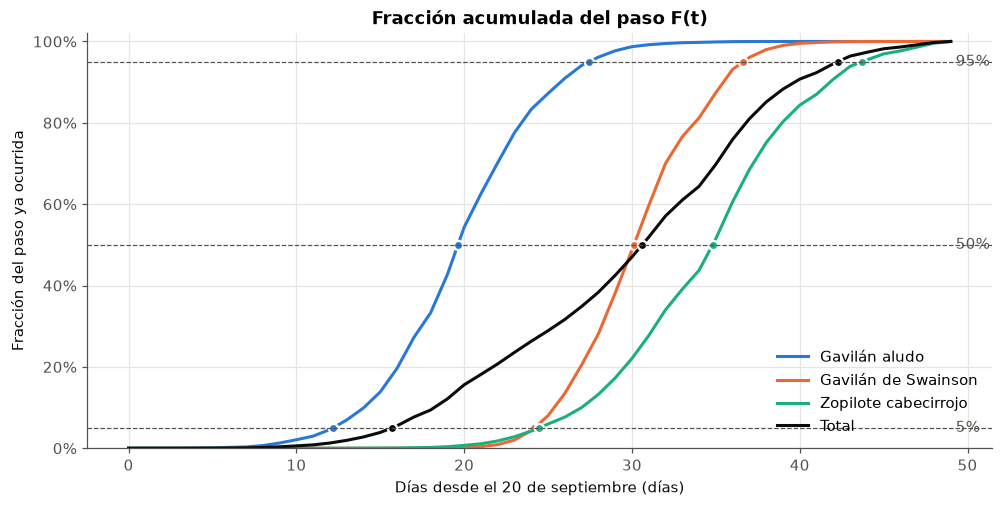

In [10]:
gr.curva_acumulada(totales, [*es.ESPECIES, "Total"]);

**Lectura:** el gavilán aludo pasa primero, el gavilán de Swainson a mitad de temporada y el zopilote cabecirrojo al final, con el paso más disperso. En las especies con cola larga hacia un lado, la fecha media y la del 50 % no coinciden: la media se "estira" hacia la cola, pero la mediana no.

### Verificación: integral vs. acumulado observado

In [11]:
pd.DataFrame(
    [{"serie": e, **verificar_total(totales[e], totales["dia"])} for e in [*es.ESPECIES, "Total"]]
)

,serie,suma,trapecio,simpson,error_trapecio,error_simpson
0,Gavilán aludo,"619,072.450","619,067.450","630,874.633",0.000,0.019
1,Gavilán de Swainson,"297,213.200","297,213.200","306,049.300",0.000,0.030
2,Zopilote cabecirrojo,"1,304,712.450","1,303,737.500","1,292,020.692",0.001,0.010
3,Total,"2,220,998.100","2,220,018.150","2,228,944.625",0.000,0.004


El trapecio coincide con la suma de los totales diarios (el acumulado observado) con un error menor que 0,1 %. Simpson se aleja hasta un 3 %, porque supone que la curva es suave (parábolas) y los datos diarios tienen saltos por la lluvia; por eso el modelo usa el trapecio.

## 6. Ventana óptima de la campaña
$$G(a)=\int_a^{a+L} n(t)\,dt,\qquad G'(a)=n(a+L)-n(a)=0$$
Por el **teorema fundamental del cálculo**, la derivada de $G$ es la tasa en el extremo final menos la tasa en el extremo inicial. En el máximo, el primer y el último día de la campaña tienen casi la misma cantidad de aves.

Mejor inicio: día 18, campaña del 08/10/2026 al 28/10/2026
Fracción del paso en esas fechas: 78.9%
{'n_inicio': 55382.520000000004, 'n_fin': 63822.5, 'diferencia_relativa': 0.13224145089897757, 'a_donde_G_prima_es_cero': 18.958169664549}


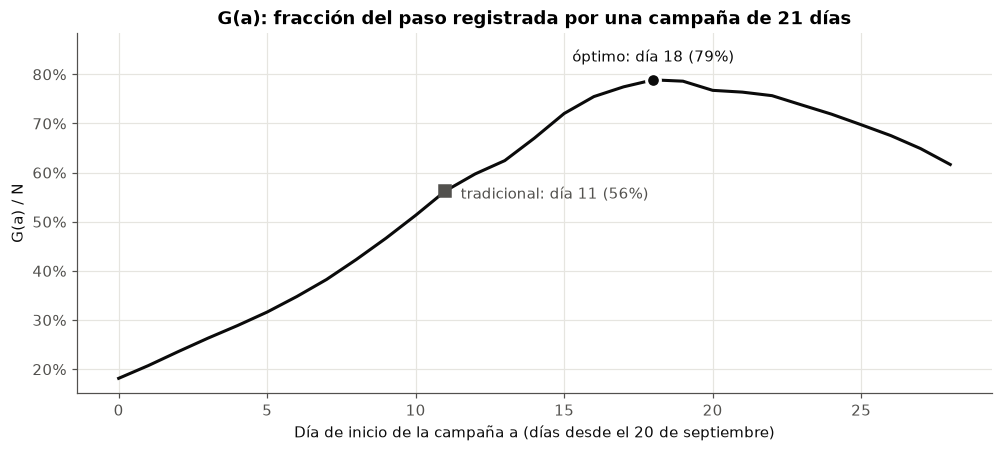

In [12]:
L = p.dias_campana
r = mejor_ventana(totales["Total"].to_numpy(), L, totales["dia"].to_numpy(float))
desde, hasta = es.dia_a_fecha(r.inicio, fecha0), es.dia_a_fecha(r.fin - 1, fecha0)
print(f"Mejor inicio: día {r.inicio:.0f}, campaña del {desde} al {hasta}")
print(f"Fracción del paso en esas fechas: {r.fraccion:.1%}")
print(es.comprobar_extremos(totales, r.inicio, L))
gr.funcion_G(totales, L, p.inicio_tradicional);

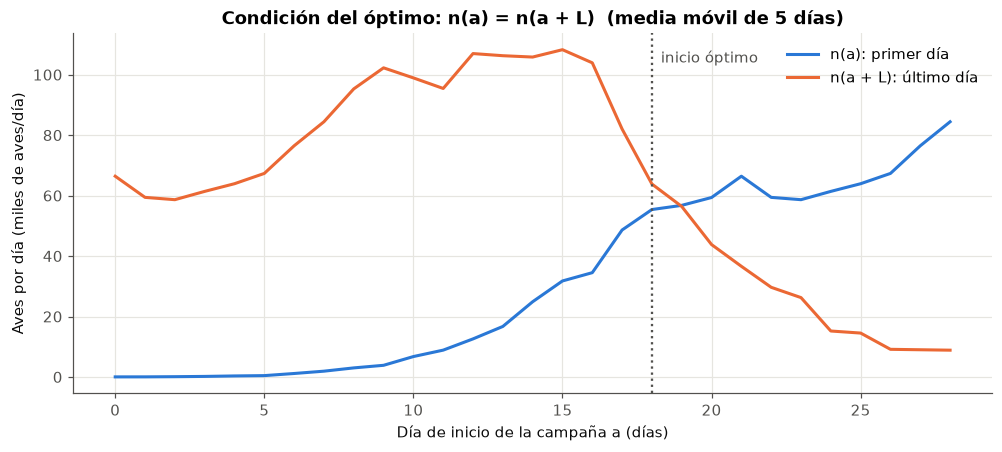

In [13]:
gr.condicion_optimo(totales, L);

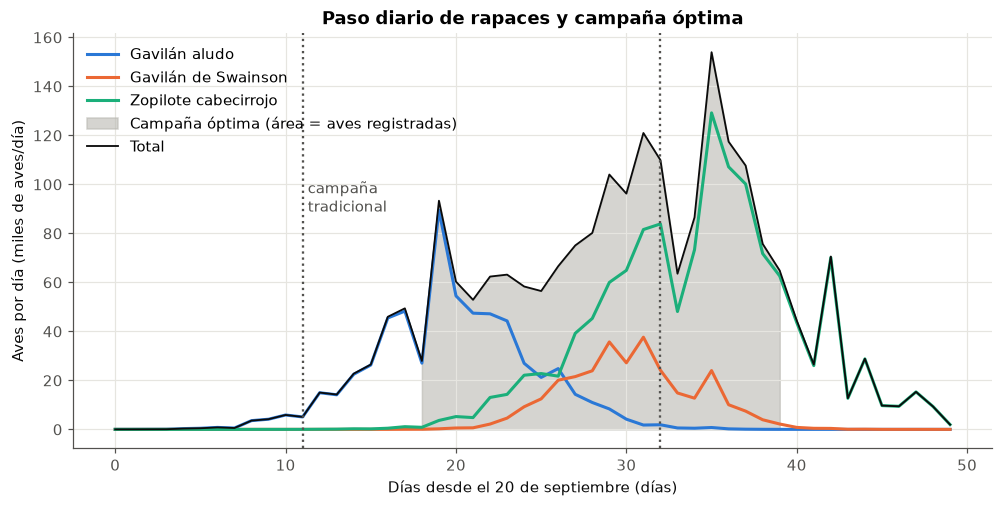

In [14]:
gr.conteos_diarios(totales, es.ESPECIES, r.inicio, L, p.inicio_tradicional);

## 7. Mejor turno
Con el perfil horario promedio de los días de la campaña se busca el bloque de horas seguidas con más aves (otra integral móvil, ahora en horas).

Mejor turno: 09:00 a 15:00  ->  79.2% de las aves del día


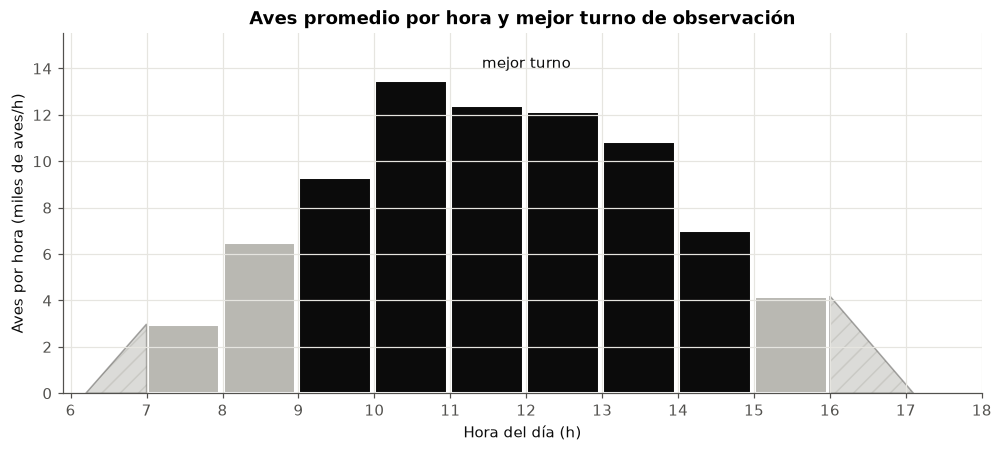

In [15]:
perfil = perfil_horario(limpio, dias=(r.inicio, r.fin))
hora_ini, frac_turno = es.fraccion_turno(limpio, r.inicio, L, p.horas_turno, p.hi, p.hf)
turno = f"{es.hora_texto(hora_ini)} a {es.hora_texto(hora_ini + p.horas_turno)}"
print(f"Mejor turno: {turno}  ->  {frac_turno:.1%} de las aves del día")
gr.perfil_y_turno(perfil, hora_ini, p.horas_turno, p.hi, p.hf);

## 8. Escenarios y sensibilidad
1. **Tradicional:** empieza el día indicado en el Excel.
2. **Centrada en el 50 %:** regla simple, se centra en la fecha del 50 % del paso.
3. **Óptima:** el máximo de G(a).
4. **Equilibrada:** maximiza el registro de la especie menos cubierta.

In [16]:
esc = es.comparar_escenarios(totales, limpio, p)
esc[
    [
        "nombre",
        "fecha_inicio",
        "fecha_fin",
        "hora_inicio",
        "hora_fin",
        "frac_fechas",
        "frac_turno",
        "frac_registrada",
        "aves_registradas",
        *[f"frac_{e}" for e in es.ESPECIES],
    ]
]

,nombre,fecha_inicio,fecha_fin,hora_inicio,hora_fin,frac_fechas,frac_turno,frac_registrada,aves_registradas,frac_Gavilán aludo,frac_Gavilán de Swainson,frac_Zopilote cabecirrojo
0,Tradicional,01/10/2026,21/10/2026,9.000,15.000,0.563,0.795,0.447,"992,725.813",0.965,0.700,0.340
1,Centrada en el 50 %,10/10/2026,30/10/2026,9.000,15.000,0.767,0.786,0.603,"1,339,765.177",0.457,0.995,0.863
2,Óptima (más aves),08/10/2026,28/10/2026,9.000,15.000,0.789,0.792,0.625,"1,386,514.920",0.667,0.990,0.801
3,Equilibrada (3 especies),07/10/2026,27/10/2026,9.000,15.000,0.775,0.794,0.615,"1,365,879.787",0.728,0.980,0.750


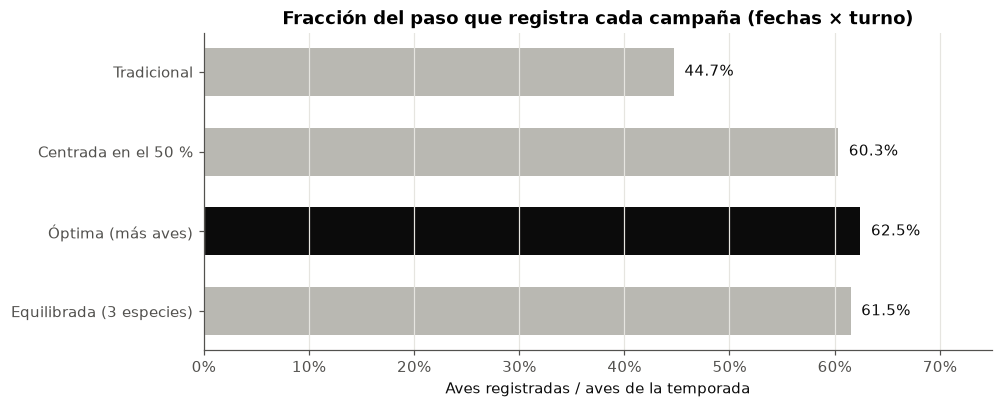

In [17]:
gr.barras_escenarios(esc);

In [18]:
print("Duración de la campaña:")
display(es.sensibilidad_duracion(totales, p, [7, 14, 21, 28, 35]))
print("Horas del turno:")
display(es.sensibilidad_turno(limpio, p, [2, 3, 4, 5, 6, 7, 8]))
print("Duración del vuelo (h_i, h_f):")
display(es.sensibilidad_vuelo(limpio, p, [-0.5, 0.0, 0.5]))
print("Criterio de limpieza:")
display(es.sensibilidad_limpieza(conteos, p, [3, 5, 10]))

Duración de la campaña:


,dias,mejor_inicio,frac_optima,frac_tradicional
0,7,30.000,0.340,0.086
1,14,25.000,0.594,0.281
2,21,18.000,0.789,0.563
3,28,15.000,0.925,0.874
4,35,12.000,0.979,0.978


Horas del turno:


,horas,hora_inicio,hora_fin,fraccion
0,2,10.000,12.000,0.317
1,3,10.000,13.000,0.460
2,4,10.000,14.000,0.594
3,5,9.000,14.000,0.704
4,6,9.000,15.000,0.792
5,7,8.000,15.000,0.871
6,8,8.000,16.000,0.922


Duración del vuelo (h_i, h_f):


,cambio_h,hi,hf,total_aves,mejor_inicio,frac_optima
0,-0.500,6.700,16.600,"2,171,723.525",18.000,0.789
1,0.000,6.200,17.100,"2,220,018.150",18.000,0.789
2,0.500,5.700,17.600,"2,268,312.775",18.000,0.789


Criterio de limpieza:


,factor,atipicos,total_aves,mejor_inicio,frac_optima
0,3,15,"2,181,167.650",18.000,0.788
1,5,4,"2,220,018.150",18.000,0.789
2,10,3,"2,220,376.650",18.000,0.789


**Lectura de la sensibilidad:** la fecha óptima (8 de octubre) no cambia al mover $h_i$ y $h_f$ ni al cambiar el criterio de limpieza; esos supuestos cambian el total estimado, pero no la decisión. El parámetro que más mueve la decisión es la **duración L** de la campaña: con más días el inicio óptimo se adelanta y la ventaja sobre la campaña tradicional se reduce.

## 9. Recomendación

In [19]:
print(es.recomendacion(esc))

Hacer la campaña del 08/10/2026 al 28/10/2026, con turno de 09:00 a 15:00. Registraría el 62% de las aves de la temporada (unas 1,386,515), frente al 45% de la campaña tradicional: 393,789 aves más.


**Condiciones y limitaciones**
- Supone que el calendario de paso de los próximos años se parece al de esta temporada. Si el paso se adelanta o atrasa, hay que mover la campaña. Se recomienda revisar cada año la fecha del 50 %.
- Los días de lluvia reducen el conteo; la campaña no puede evitar la lluvia, pero sí concentrarse en las semanas de mayor paso.
- La campaña óptima registra menos gavilán aludo que la tradicional, porque esta especie pasa antes. Si el programa quiere priorizar esa especie, conviene la opción *equilibrada*.